In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/drive/Shareddrives/ai/cleaned_data.csv")

In [ ]:
print('Dataset shape:', df.shape)
print('Column names:', df.columns.tolist())
df.head()

Dataset shape: (9901, 16)
Column names: ['Customer ID', 'Subscription Length (Months)', 'Customer Satisfaction Score (1-10)', 'Daily Watch Time (Hours)', 'Engagement Rate (1-10)', 'Device Used Most Often', 'Genre Preference', 'Region', 'Payment History (On-Time/Delayed)', 'Subscription Plan', 'Churn Status (Yes/No)', 'Support Queries Logged', 'Age', 'Monthly Income ($)', 'Promotional Offers Used', 'Number of Profiles Created']


,Customer ID,Subscription Length (Months),Customer Satisfaction Score (1-10),Daily Watch Time (Hours),Engagement Rate (1-10),Device Used Most Often,Genre Preference,Region,Payment History (On-Time/Delayed),Subscription Plan,Churn Status (Yes/No),Support Queries Logged,Age,Monthly Income ($),Promotional Offers Used,Number of Profiles Created
0,CUST109419,62.0,8.0,1.45,2.0,Smartphone,comedy,north-america,delayed,standard,NO,1.0,41.0,22495.0,0.0,2.0
1,CUST108768,54.0,7.0,5.10,7.0,Laptop,thriller,north-america,on-time,basic,NO,0.0,30.0,70506.0,2.0,1.0
2,CUST107656,25.0,6.0,3.78,6.0,Tablet,sci-fi,north-america,on-time,standard,NO,1.0,24.0,67448.0,2.0,4.0
3,CUST100416,31.0,8.0,2.28,3.0,Tablet,drama,latin-america,on-time,basic,NO,1.0,48.0,65227.5,0.0,3.0
4,CUST103710,19.0,5.0,2.84,5.0,Smartphone,drama,asia-pacific,on-time,basic,NO,2.0,41.0,31250.0,0.0,1.0


In [ ]:
# Check that the columns required for this EDA are present.
required_columns = [
    'Churn Status (Yes/No)',
    'Customer Satisfaction Score (1-10)',
    'Daily Watch Time (Hours)',
    'Engagement Rate (1-10)',
    'Device Used Most Often',
    'Genre Preference',
    'Region',
    'Payment History (On-Time/Delayed)',
    'Subscription Plan',
    'Support Queries Logged',
    'Subscription Length (Months)',
    'Age'
]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f'Missing required columns: {missing_columns}')

print('Missing values by column:')
print(df.isnull().sum())
df.head()

Missing values by column:
Customer ID                           0
Subscription Length (Months)          0
Customer Satisfaction Score (1-10)    0
Daily Watch Time (Hours)              0
Engagement Rate (1-10)                0
Device Used Most Often                0
Genre Preference                      0
Region                                0
Payment History (On-Time/Delayed)     0
Subscription Plan                     0
Churn Status (Yes/No)                 0
Support Queries Logged                0
Age                                   0
Monthly Income ($)                    0
Promotional Offers Used               0
Number of Profiles Created            0
dtype: int64


,Customer ID,Subscription Length (Months),Customer Satisfaction Score (1-10),Daily Watch Time (Hours),Engagement Rate (1-10),Device Used Most Often,Genre Preference,Region,Payment History (On-Time/Delayed),Subscription Plan,Churn Status (Yes/No),Support Queries Logged,Age,Monthly Income ($),Promotional Offers Used,Number of Profiles Created
0,CUST109419,62.0,8.0,1.45,2.0,Smartphone,comedy,north-america,delayed,standard,NO,1.0,41.0,22495.0,0.0,2.0
1,CUST108768,54.0,7.0,5.10,7.0,Laptop,thriller,north-america,on-time,basic,NO,0.0,30.0,70506.0,2.0,1.0
2,CUST107656,25.0,6.0,3.78,6.0,Tablet,sci-fi,north-america,on-time,standard,NO,1.0,24.0,67448.0,2.0,4.0
3,CUST100416,31.0,8.0,2.28,3.0,Tablet,drama,latin-america,on-time,basic,NO,1.0,48.0,65227.5,0.0,3.0
4,CUST103710,19.0,5.0,2.84,5.0,Smartphone,drama,asia-pacific,on-time,basic,NO,2.0,41.0,31250.0,0.0,1.0


In [ ]:
churn_counts = df['Churn Status (Yes/No)'].astype('string').str.strip().str.title().value_counts()
print(churn_counts)

Churn Status (Yes/No)
No     7432
Yes    2469
Name: count, dtype: Int64


In [ ]:
churn_percentage = df['Churn Status (Yes/No)'].astype('string').str.strip().str.title().value_counts(normalize=True) * 100
print(churn_percentage.round(2))

Churn Status (Yes/No)
No     75.06
Yes    24.94
Name: proportion, dtype: Float64


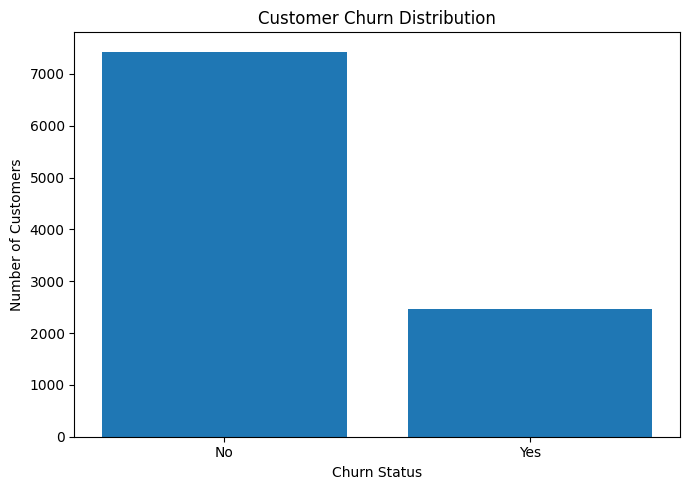

In [ ]:
plt.figure(figsize=(7, 5))
plt.bar(churn_counts.index.astype(str), churn_counts.values)
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')
plt.title('Customer Churn Distribution')
plt.tight_layout()
plt.show()

<Figure size 800x500 with 0 Axes>

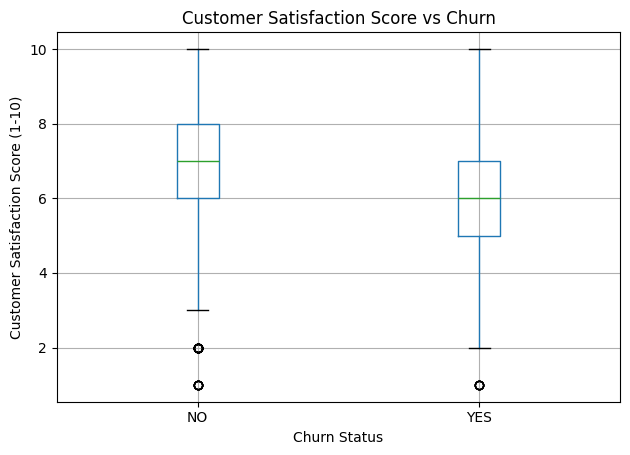

In [ ]:
plt.figure(figsize=(8, 5))
df.boxplot(column='Customer Satisfaction Score (1-10)', by='Churn Status (Yes/No)')
plt.title('Customer Satisfaction Score vs Churn')
plt.suptitle('')
plt.xlabel('Churn Status')
plt.ylabel('Customer Satisfaction Score (1-10)')
plt.tight_layout()
plt.show()

In [ ]:
satisfaction_avg = df.groupby('Churn Status (Yes/No)')['Customer Satisfaction Score (1-10)'].mean()
print(satisfaction_avg.round(2))
if {'Yes', 'No'}.issubset(set(satisfaction_avg.index.astype(str))):
    print('Absolute mean difference:', round(abs(satisfaction_avg['Yes'] - satisfaction_avg['No']), 2))

Churn Status (Yes/No)
NO     7.20
YES    6.33
Name: Customer Satisfaction Score (1-10), dtype: float64


In [ ]:
watch_time_avg = df.groupby('Churn Status (Yes/No)')['Daily Watch Time (Hours)'].mean()
print(watch_time_avg.round(2))

Churn Status (Yes/No)
NO     2.23
YES    1.60
Name: Daily Watch Time (Hours), dtype: float64


<Figure size 800x500 with 0 Axes>

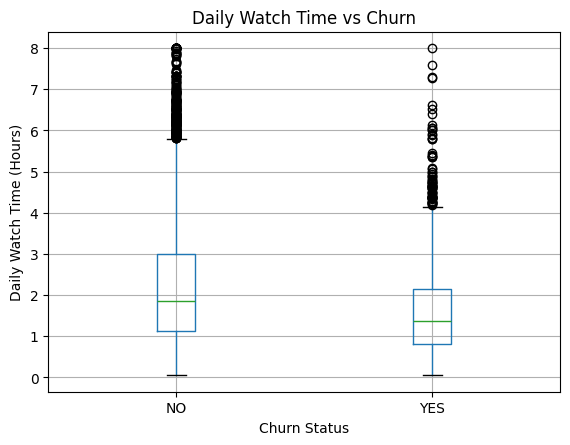

In [ ]:
plt.figure(figsize=(8, 5))
df.boxplot(column='Daily Watch Time (Hours)', by='Churn Status (Yes/No)')
plt.title('Daily Watch Time vs Churn')
plt.suptitle('')
plt.xlabel('Churn Status')
plt.ylabel('Daily Watch Time (Hours)')
plt.show()

In [ ]:
engagement_avg = df.groupby('Churn Status (Yes/No)')['Engagement Rate (1-10)'].mean()
print(engagement_avg.round(2))

Churn Status (Yes/No)
NO     4.35
YES    3.40
Name: Engagement Rate (1-10), dtype: float64


<Figure size 800x500 with 0 Axes>

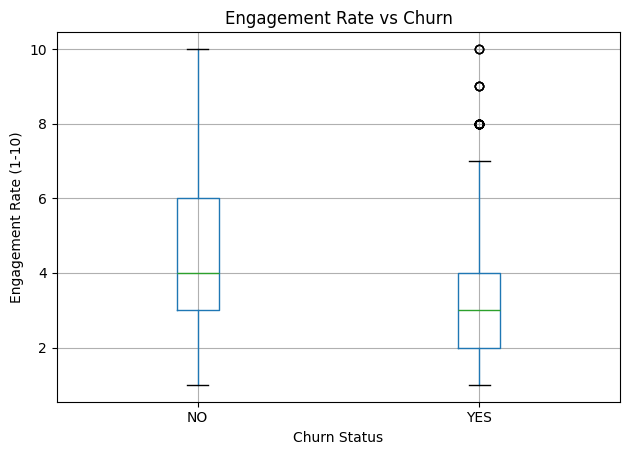

In [ ]:
plt.figure(figsize=(8, 5))
df.boxplot(column='Engagement Rate (1-10)', by='Churn Status (Yes/No)')
plt.title('Engagement Rate vs Churn')
plt.suptitle('')
plt.xlabel('Churn Status')
plt.ylabel('Engagement Rate (1-10)')
plt.tight_layout()
plt.show()

In [ ]:
device_churn = pd.crosstab(
    df['Device Used Most Often'].fillna('Missing').astype(str).str.strip(),
    df['Churn Status (Yes/No)'].fillna('Missing').astype(str).str.strip().str.title(),
    normalize='index'
) * 100
print(device_churn.round(2))

Churn Status (Yes/No)      No    Yes
Device Used Most Often              
Laptop                  74.06  25.94
Smart Tv                75.03  24.97
Smartphone              74.78  25.22
Tablet                  78.02  21.98


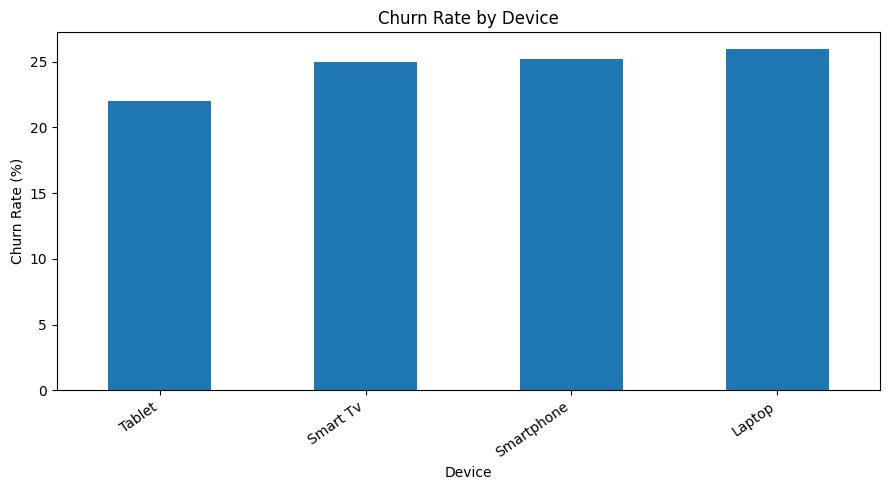

In [ ]:
if 'Yes' in device_churn.columns:
    device_churn['Yes'].sort_values().plot(kind='bar', figsize=(9, 5))
    plt.xlabel('Device')
    plt.ylabel('Churn Rate (%)')
    plt.title('Churn Rate by Device')
    plt.xticks(rotation=35, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No 'Yes' churn category found; check target labels.")

In [ ]:
genre_churn = pd.crosstab(
    df['Genre Preference'].fillna('Missing').astype(str).str.strip(),
    df['Churn Status (Yes/No)'].fillna('Missing').astype(str).str.strip().str.title(),
    normalize='index'
) * 100
print(genre_churn.round(2))

Churn Status (Yes/No)     No    Yes
Genre Preference                   
action                 75.53  24.47
comedy                 75.07  24.93
documentary            74.79  25.21
drama                  75.75  24.25
sci-fi                 73.59  26.41
thriller               75.63  24.37


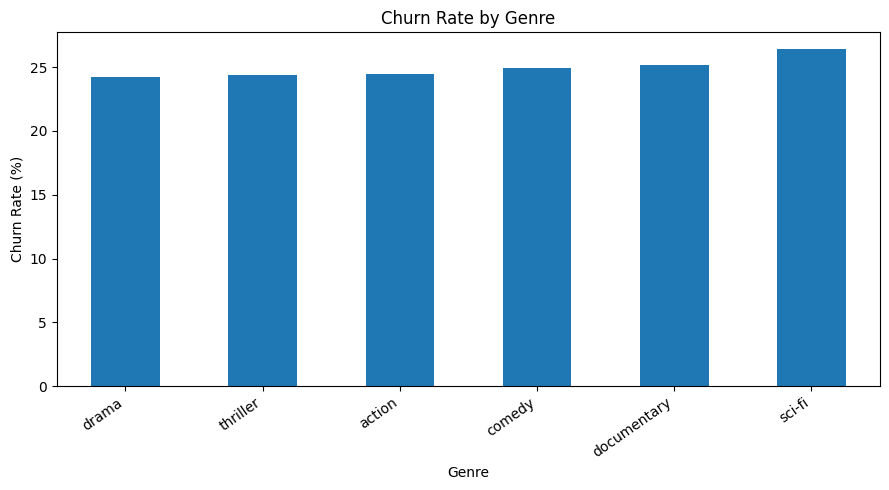

In [ ]:
if 'Yes' in genre_churn.columns:
    genre_churn['Yes'].sort_values().plot(kind='bar', figsize=(9, 5))
    plt.xlabel('Genre')
    plt.ylabel('Churn Rate (%)')
    plt.title('Churn Rate by Genre')
    plt.xticks(rotation=35, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No 'Yes' churn category found; check target labels.")

In [ ]:
region_churn = pd.crosstab(
    df['Region'].fillna('Missing').astype(str).str.strip(),
    df['Churn Status (Yes/No)'].fillna('Missing').astype(str).str.strip().str.title(),
    normalize='index'
) * 100
print(region_churn.round(2))

Churn Status (Yes/No)     No    Yes
Region                             
asia-pacific           75.12  24.88
europe                 74.74  25.26
latin-america          75.84  24.16
north-america          74.98  25.02


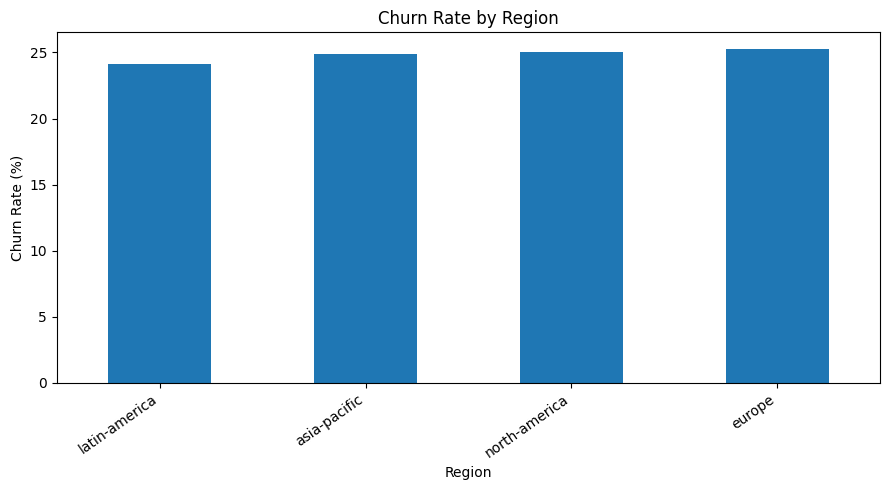

In [ ]:
if 'Yes' in region_churn.columns:
    region_churn['Yes'].sort_values().plot(kind='bar', figsize=(9, 5))
    plt.xlabel('Region')
    plt.ylabel('Churn Rate (%)')
    plt.title('Churn Rate by Region')
    plt.xticks(rotation=35, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No 'Yes' churn category found; check target labels.")

In [ ]:
payment_churn = pd.crosstab(
    df['Payment History (On-Time/Delayed)'].fillna('Missing').astype(str).str.strip(),
    df['Churn Status (Yes/No)'].fillna('Missing').astype(str).str.strip().str.title(),
    normalize='index'
) * 100
print(payment_churn.round(2))

Churn Status (Yes/No)                 No    Yes
Payment History (On-Time/Delayed)              
delayed                            66.38  33.62
on-time                            77.41  22.59


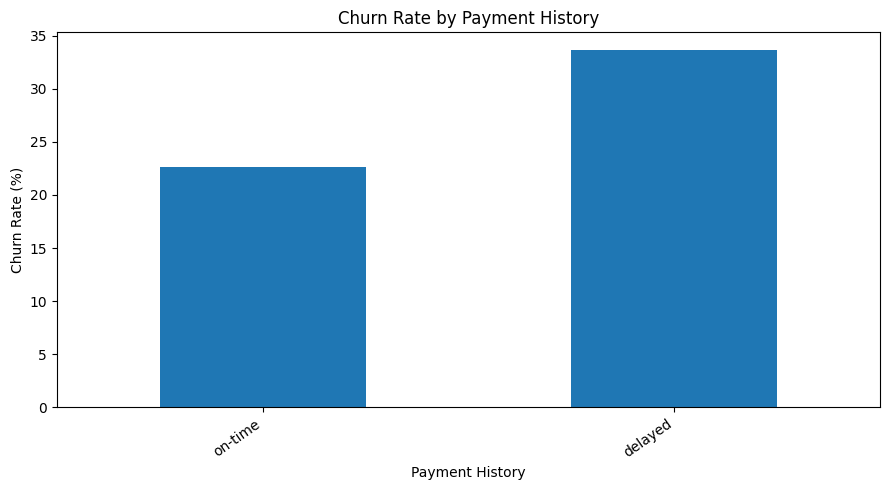

In [ ]:
if 'Yes' in payment_churn.columns:
    payment_churn['Yes'].sort_values().plot(kind='bar', figsize=(9, 5))
    plt.xlabel('Payment History')
    plt.ylabel('Churn Rate (%)')
    plt.title('Churn Rate by Payment History')
    plt.xticks(rotation=35, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No 'Yes' churn category found; check target labels.")

In [ ]:
plan_churn = pd.crosstab(
    df['Subscription Plan'].fillna('Missing').astype(str).str.strip(),
    df['Churn Status (Yes/No)'].fillna('Missing').astype(str).str.strip().str.title(),
    normalize='index'
) * 100
print(plan_churn.round(2))

Churn Status (Yes/No)     No    Yes
Subscription Plan                  
basic                  73.22  26.78
premium                75.23  24.77
standard               76.21  23.79


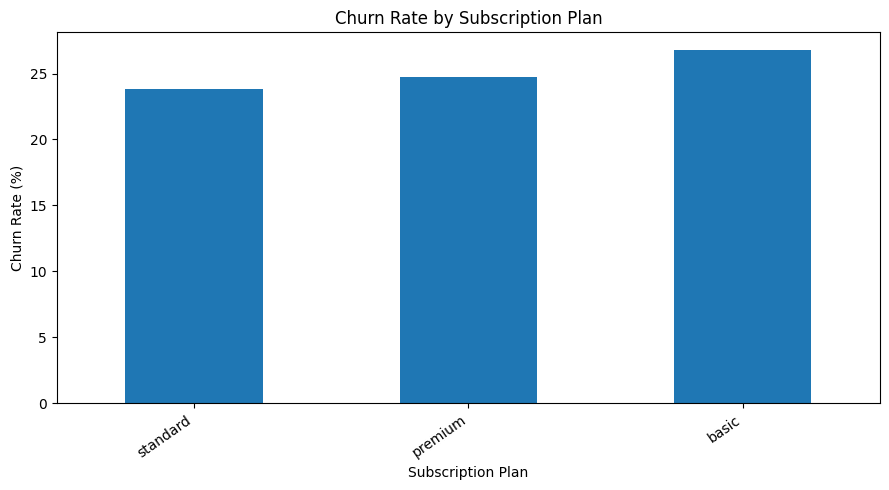

In [ ]:
if 'Yes' in plan_churn.columns:
    plan_churn['Yes'].sort_values().plot(kind='bar', figsize=(9, 5))
    plt.xlabel('Subscription Plan')
    plt.ylabel('Churn Rate (%)')
    plt.title('Churn Rate by Subscription Plan')
    plt.xticks(rotation=35, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No 'Yes' churn category found; check target labels.")

In [ ]:
support_avg = df.groupby('Churn Status (Yes/No)')['Support Queries Logged'].mean()
print(support_avg.round(2))

Churn Status (Yes/No)
NO     1.42
YES    1.67
Name: Support Queries Logged, dtype: float64


<Figure size 800x500 with 0 Axes>

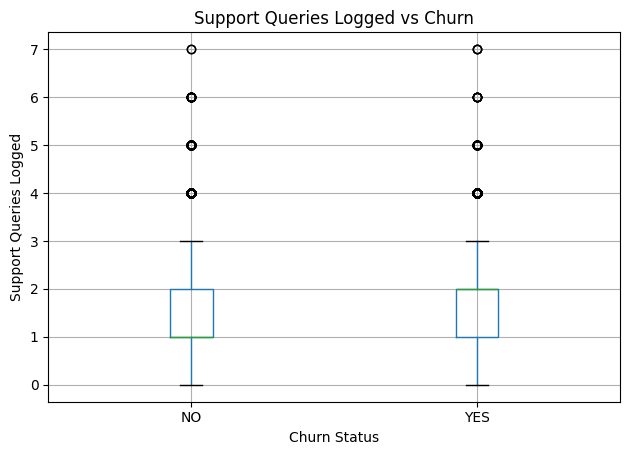

In [ ]:
plt.figure(figsize=(8, 5))
df.boxplot(column='Support Queries Logged', by='Churn Status (Yes/No)')
plt.title('Support Queries Logged vs Churn')
plt.suptitle('')
plt.xlabel('Churn Status')
plt.ylabel('Support Queries Logged')
plt.tight_layout()
plt.show()

In [ ]:
subscription_length_avg = df.groupby('Churn Status (Yes/No)')['Subscription Length (Months)'].mean()
print(subscription_length_avg.round(2))

Churn Status (Yes/No)
NO     37.65
YES    32.86
Name: Subscription Length (Months), dtype: float64


<Figure size 800x500 with 0 Axes>

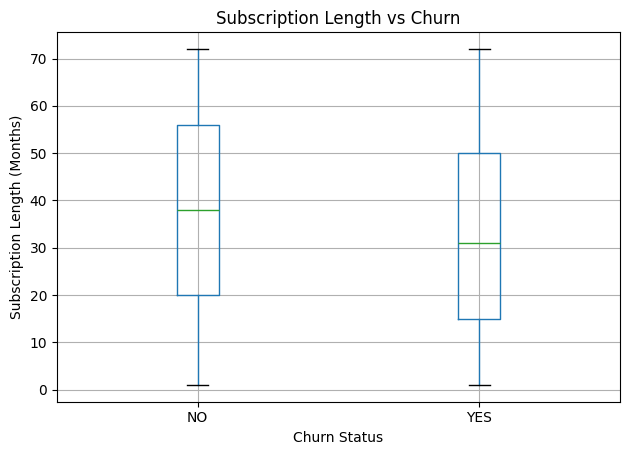

In [ ]:
plt.figure(figsize=(8, 5))
df.boxplot(column='Subscription Length (Months)', by='Churn Status (Yes/No)')
plt.title('Subscription Length vs Churn')
plt.suptitle('')
plt.xlabel('Churn Status')
plt.ylabel('Subscription Length (Months)')
plt.tight_layout()
plt.show()

In [ ]:
age_avg = df.groupby('Churn Status (Yes/No)')['Age'].mean()
print(age_avg.round(2))

Churn Status (Yes/No)
NO     36.16
YES    36.07
Name: Age, dtype: float64


<Figure size 800x500 with 0 Axes>

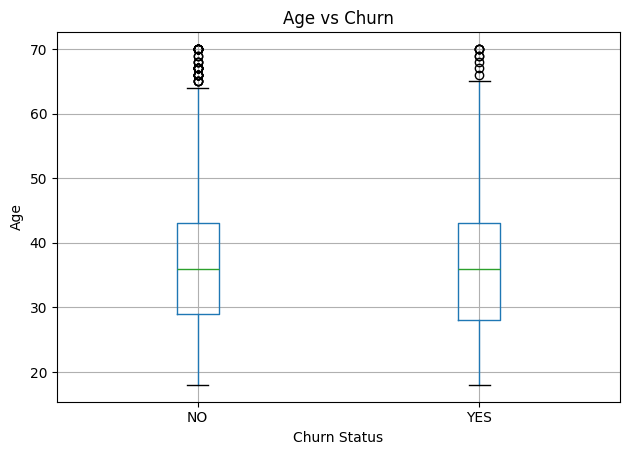

In [ ]:
plt.figure(figsize=(8, 5))
df.boxplot(column='Age', by='Churn Status (Yes/No)')
plt.title('Age vs Churn')
plt.suptitle('')
plt.xlabel('Churn Status')
plt.ylabel('Age')
plt.tight_layout()
plt.show()

In [ ]:
# Standardize target labels before creating the numeric target.
df['Churn Status (Yes/No)'] = df['Churn Status (Yes/No)'].astype('string').str.strip().str.title()
invalid_targets = df.loc[~df['Churn Status (Yes/No)'].isin(['Yes', 'No']), 'Churn Status (Yes/No)'].dropna().unique()
if len(invalid_targets) > 0:
    print('Unrecognized churn labels:', invalid_targets)
df['Churn_Numeric'] = df['Churn Status (Yes/No)'].map({'No': 0, 'Yes': 1})
print(df['Churn_Numeric'].value_counts(dropna=False))

Churn_Numeric
0    7432
1    2469
Name: count, dtype: int64


In [ ]:
numeric_df = df.select_dtypes(include='number').copy()
print('Numeric columns:', numeric_df.columns.tolist())
print('Numeric feature correlation with churn:')
if 'Churn_Numeric' in numeric_df.columns:
    churn_correlation = numeric_df.corr(numeric_only=True)['Churn_Numeric'].drop('Churn_Numeric').sort_values(ascending=False)
    print(churn_correlation.round(3))

Numeric columns: ['Subscription Length (Months)', 'Customer Satisfaction Score (1-10)', 'Daily Watch Time (Hours)', 'Engagement Rate (1-10)', 'Support Queries Logged', 'Age', 'Monthly Income ($)', 'Promotional Offers Used', 'Number of Profiles Created', 'Churn_Numeric']
Numeric feature correlation with churn:
Support Queries Logged                0.090
Number of Profiles Created            0.011
Promotional Offers Used               0.010
Age                                  -0.004
Monthly Income ($)                   -0.027
Subscription Length (Months)         -0.100
Daily Watch Time (Hours)             -0.191
Engagement Rate (1-10)               -0.215
Customer Satisfaction Score (1-10)   -0.218
Name: Churn_Numeric, dtype: float64


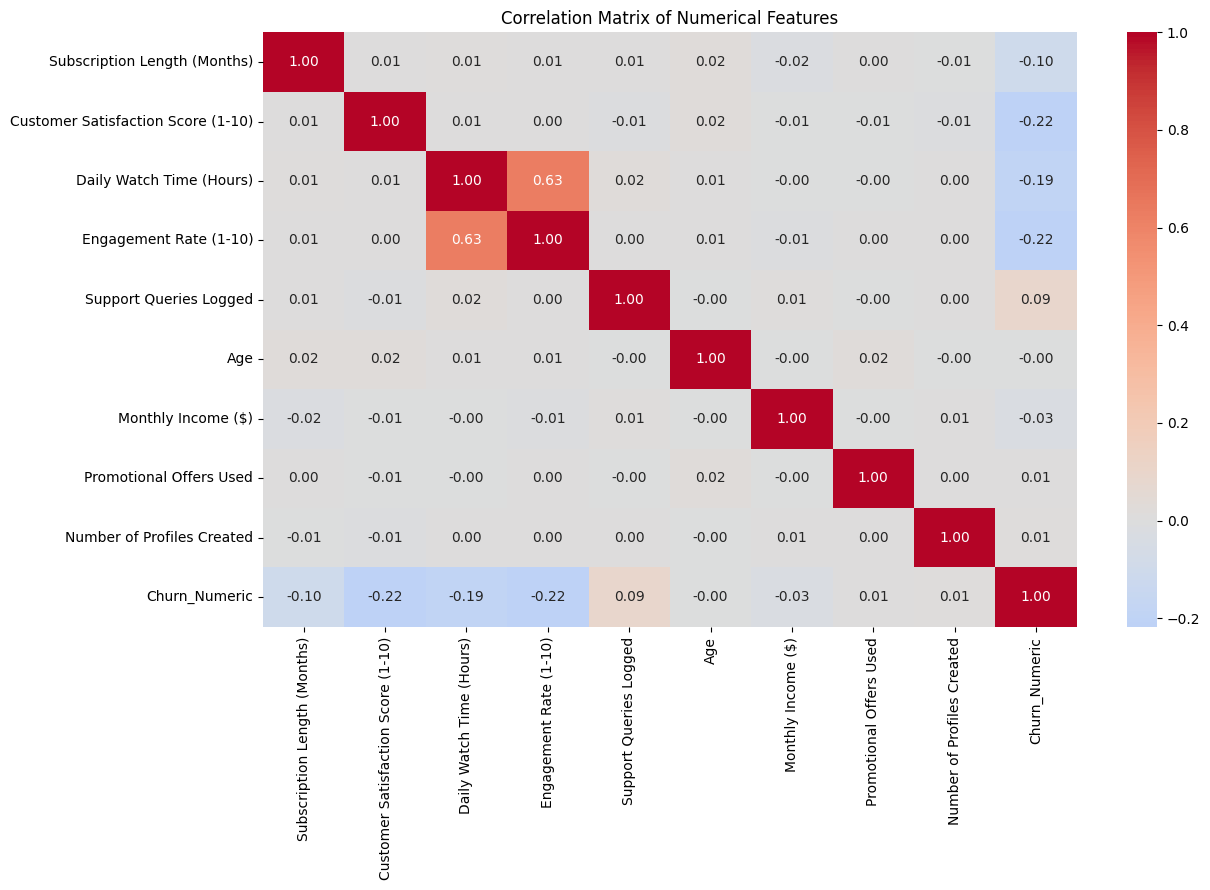

In [ ]:
corr_matrix = numeric_df.corr(numeric_only=True)
plt.figure(figsize=(13, 9))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Numerical Features')
plt.tight_layout()
plt.show()